# Задание 5. Создание сверточной сети для CIFAR10

Создайте сверточную сеть на Pytorch и обучите ее на СIFAR10. Цель получить лучшее качество чем у полносвязанной сети которую мы обучали в лекции про нейронные сети.  

* Используйте не более трёх [сверточных](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) и не более двух [полносвязанных](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) слоев, а также один слой [пулинга](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) между ними (слой пулинга и аргумент stride у сверточных слоев помогут избежать большой размерности на входе в линейный слой).
* Функцию активации выберите на свое усмотрение.  
* Не применяйте слои других типов.  
* Используйте код для обучения из лекции.

In [ ]:
from torch.nn.modules.pooling import MaxPool2d
import torch.nn as nn
import torch
import torch.nn.functional as F


class TwoLayerCNN(nn.Module):
    def __init__(self):
      super().__init__()
      self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64*8*8, 100),
            nn.ReLU(),
            nn.Linear(100, 10)
        )

    def forward(self, x):
        x = self.conv_stack(x)
        return x

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


Загрузите CIFAR10:

In [ ]:
from tqdm import trange
import torchvision
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
import random
import numpy as np


def set_random_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

from torch.utils.data import random_split
transform = torchvision.transforms.Compose([torchvision.transforms.ToTensor()])

set_random_seed(42)

dataset = CIFAR10(root='./CIFAR10', train=True, download=True, transform=transform)
testset = CIFAR10(root='./CIFAR10', train=False, download=True, transform=transform)


trainset, valset  = random_split(dataset, [47000, 3000])


batch_size = 256

train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=2)

@torch.inference_mode()
def get_correct_count(pred,labels):
  _, predicted = torch.max(pred.data, 1)
  return (predicted == labels).sum().item()

@torch.inference_mode()
def calaculate_accuracy(model, data_loader, criterion, device='cpu'):
    correct, total = 0, 0
    loss = 0
    for batch in data_loader:
        imgs, labels = batch
        imgs, labels = imgs.to(device), labels.to(device)
        pred = model(imgs.to(device))
        loss += criterion(pred, labels)
        correct += get_correct_count(pred,labels)
        total += labels.size(0)

    return correct / total , loss.item() / len(data_loader)

Using device: cpu


100%|██████████| 170M/170M [17:08<00:00, 166kB/s]


In [ ]:
from IPython.display import clear_output
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

class ProgressPlotter:
  def __init__(self,title = None) -> None:
    self._history_dict = defaultdict(list)
    self.title = title

  def add_scalar(self, tag: str, value)-> None:
    self._history_dict[tag].append(value)

  def display_keys(self,ax,tags):
    if isinstance(tags, str):
      tags = [tags]
    history_len = 0
    ax.grid()
    for key in tags:
      ax.plot(self._history_dict[key], marker="X",label=key)
      history_len = max(history_len,len(self.history_dict[key]))
    if len(tags) > 1:
      ax.legend(loc="lower left")
    else:
      ax.set_ylabel(key)
    ax.set_xlabel('step')
    ax.set_xticks(np.arange(history_len))
    ax.set_xticklabels(np.arange(history_len))

  """
     groups list of keys like [['loss_train','loss_val'],['accuracy']]
     All charts within a group will be plot in the same axis
  """
  def display(self,groups = None):
    clear_output()
    if groups is None:
      groups = self._history_dict.keys()
    n_groups = len(groups)
    fig, ax = plt.subplots(n_groups, 1, figsize=(12, 3*n_groups))
    fig.suptitle(self.title)
    if n_groups == 1:
      ax = [ax]
    for i, keys in enumerate(groups):
      self.display_keys(ax[i],keys)
    fig.tight_layout()
    plt.show()

  @property
  def history_dict(self):
    return dict(self._history_dict)

Разместите код для обучения в этом блоке.

Используйте GPU. Для этого Вам необходимо в верхней панели выбрать `Среда выполнения > Сменить среду выполнения` и заменить None на GPU.

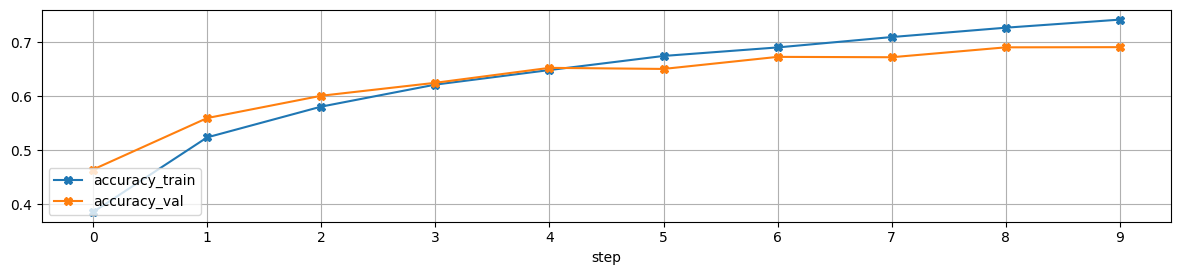

In [ ]:
def train(model, criterion, optimizer, num_epochs=10, tag="cifar10"):
    pp = ProgressPlotter()
    for epoch in range(num_epochs):
        correct, total, ep_loss = 0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            correct += get_correct_count(outputs,labels)
            loss.backward()
            optimizer.step()
            total += labels.size(0)
            ep_loss += loss.item()
        # Logging

        pp.add_scalar('accuracy_train', correct/total)

        accuracy, _ = calaculate_accuracy(model,val_loader,criterion, device)

        pp.add_scalar('accuracy_val',accuracy)

        pp.display([['accuracy_train','accuracy_val']])
    return pp


set_random_seed(42)


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
model = TwoLayerCNN()  # Create model instance
model.train().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss() # Loss function
pp = train(model, criterion, optimizer, num_epochs=10)

In [ ]:
testset.transform = transform
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)
accuracy, loss_val = calaculate_accuracy(model,test_loader,criterion, device)
print(f"Accuracy {accuracy:.2f}")

Accuracy 0.69


## Формат результата

Результатом является сверточная сеть обученная на CIFAR10, с точностью не ниже 0.6